##  Imports et chargement

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

import networkx as nx

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Adapter le chemin si le fichier est dans un dossier Google Drive.
df_brut = pd.read_csv("orchard_surveys.csv")

print("Dimensions :", df_brut.shape)
display(df_brut.head())

Dimensions : (1250, 11)


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,NaN
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,NaN
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,NaN
3,ORC-0000004,AVL-MAR,2019-04-01,24.1,90.2,48.7,21992.9,67.4,22.8,36.3,NaN
4,ORC-0000005,AVL-MAR,2019-05-01,24.1,80.7,61.4,27213.5,62.9,31.9,40.7,NaN


## structure des données

In [2]:
print("Informations générales")
df_brut.info()

print("\\nStatistiques descriptives")
display(df_brut.describe(include="all").T)

print("\\nNombre de valeurs distinctes")
display(df_brut.nunique().sort_values(ascending=False).to_frame("valeurs_distinctes"))

print("\\nValeurs manquantes")
manquants = df_brut.isna().sum().to_frame("nombre")
manquants["pourcentage"] = (manquants["nombre"] / len(df_brut) * 100).round(2)
display(manquants.sort_values("pourcentage", ascending=False))

print("\\nNombre de lignes et d'identifiants")
print("Lignes :", len(df_brut))
print("Identifiants d'enquête distincts :", df_brut["orchard_survey_id"].nunique())
print("Sites distincts :", df_brut["site_code"].nunique())
print("Périodes distinctes :", df_brut["survey_period"].nunique())

Informations générales
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1250 entries, 0 to 1249
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   orchard_survey_id              1250 non-null   object 
 1   site_code                      1250 non-null   object 
 2   survey_period                  1250 non-null   object 
 3   orchard_area_ha                1250 non-null   object 
 4   durian_flower_density          1250 non-null   object 
 5   fruit_set_rate_pct             1250 non-null   float64
 6   durian_yield_kg                1250 non-null   object 
 7   other_pollinator_activity      1250 non-null   float64
 8   fertilizer_use_index           1250 non-null   object 
 9   irrigation_level               1250 non-null   float64
 10  agricultural_disturbance_note  23 non-null     object 
dtypes: float64(3), object(8)
memory usage: 107.6+ KB
\nStatistiques descriptives


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
orchard_survey_id,1250,1248,ORC-0001190,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
site_code,1250,16,TMB-HQL,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
survey_period,1250,78,2021-11-01,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orchard_area_ha,1250,21,24.1,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
durian_flower_density,1250,589,100.0,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fruit_set_rate_pct,1250.0,NaN,NaN,NaN,53.188015,10.227587,0.467,46.9,52.8,59.4,87.7
durian_yield_kg,1250,1246,51003.3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
other_pollinator_activity,1250.0,NaN,NaN,NaN,59.4412,9.382119,27.9,53.3,59.5,65.7,93.7
fertilizer_use_index,1250,418,34.4,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
irrigation_level,1250.0,NaN,NaN,NaN,39.97568,9.119255,11.5,33.8,39.55,45.5,81.0


\nNombre de valeurs distinctes


,valeurs_distinctes
orchard_survey_id,1248
durian_yield_kg,1246
durian_flower_density,589
fertilizer_use_index,418
fruit_set_rate_pct,389
other_pollinator_activity,381
irrigation_level,377
survey_period,78
orchard_area_ha,21
site_code,16


\nValeurs manquantes


,nombre,pourcentage
agricultural_disturbance_note,1227,98.16
site_code,0,0.00
orchard_survey_id,0,0.00
survey_period,0,0.00
orchard_area_ha,0,0.00
fruit_set_rate_pct,0,0.00
durian_flower_density,0,0.00
durian_yield_kg,0,0.00
other_pollinator_activity,0,0.00
fertilizer_use_index,0,0.00


\nNombre de lignes et d'identifiants
Lignes : 1250
Identifiants d'enquête distincts : 1248
Sites distincts : 16
Périodes distinctes : 78


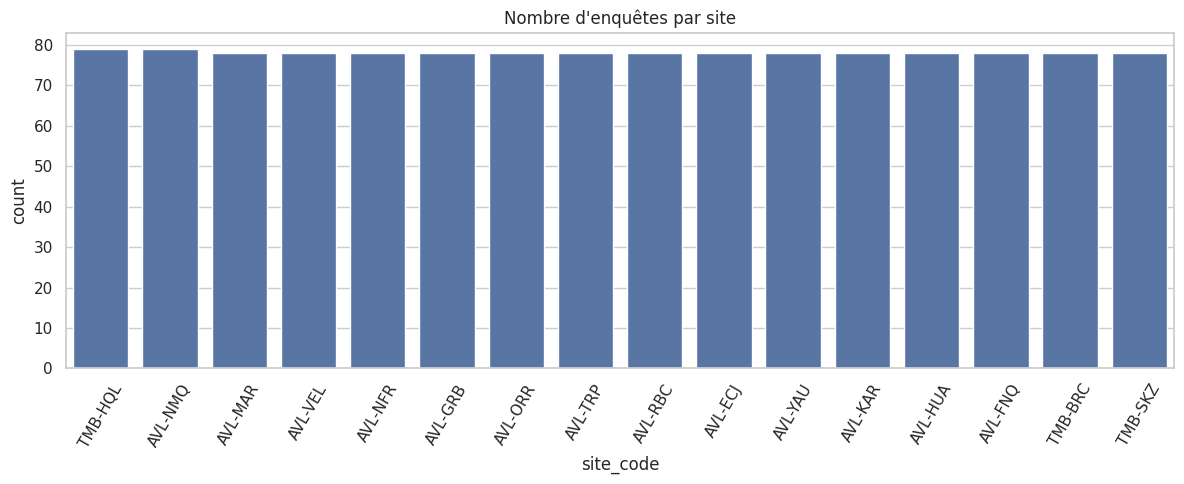

Notes de terrain renseignées : 23


,count
agricultural_disturbance_note,
NaN,1227
storm-related flower loss,15
storm-related flower loss,3
elevated pesticide application,3
elevated pesticide application,2


In [3]:
# Répartition des enquêtes par site
plt.figure(figsize=(12, 5))
ordre = df_brut["site_code"].value_counts().index
sns.countplot(data=df_brut, x="site_code", order=ordre)
plt.xticks(rotation=60)
plt.title("Nombre d'enquêtes par site")
plt.tight_layout()
plt.show()

# Répartition des notes de terrain
print("Notes de terrain renseignées :", df_brut["agricultural_disturbance_note"].notna().sum())
display(df_brut["agricultural_disturbance_note"].value_counts(dropna=False))

##  Qualité des données et nettoyage



In [4]:
df = df_brut.copy()

# 2.1 Doublons exacts et identifiants
print("Doublons exacts avant nettoyage :", df.duplicated().sum())
print("Identifiants dupliqués :", df["orchard_survey_id"].duplicated().sum())

df = df.drop_duplicates().copy()

# Si un même identifiant apparaît encore avec des contenus différents,
# on le signale au lieu de supprimer arbitrairement une ligne.
print("Doublons exacts après nettoyage :", df.duplicated().sum())
print("Identifiants encore dupliqués :", df["orchard_survey_id"].duplicated().sum())

# 2.2 Conversion des colonnes numériques contenant parfois des unités/virgules
colonnes_numeriques = [
    "orchard_area_ha",
    "durian_flower_density",
    "fruit_set_rate_pct",
    "durian_yield_kg",
    "other_pollinator_activity",
    "fertilizer_use_index",
    "irrigation_level"
]

def convertir_nombre(serie):
    texte = serie.astype("string").str.strip()
    texte = texte.str.replace(",", ".", regex=False)
    # Retire les unités éventuelles et conserve le signe, les chiffres et le point décimal.
    texte = texte.str.replace(r"[^0-9.\\-]", "", regex=True)
    texte = texte.replace("", pd.NA)
    return pd.to_numeric(texte, errors="coerce")

for col in colonnes_numeriques:
    avant = df[col].notna().sum()
    df[col] = convertir_nombre(df[col])
    apres = df[col].notna().sum()
    print(f"{col}: {avant} valeurs renseignées avant conversion, {apres} après")

# 2.3 Dates
df["survey_period"] = pd.to_datetime(df["survey_period"], errors="coerce")
print("Dates non converties :", df["survey_period"].isna().sum())

# 2.4 Nettoyage léger des notes : minuscules et espaces normalisés
df["agricultural_disturbance_note"] = (
    df["agricultural_disturbance_note"]
    .astype("string")
    .str.lower()
    .str.strip()
    .str.replace(r"\\s+", " ", regex=True)
)
df["agricultural_disturbance_note"] = df["agricultural_disturbance_note"].replace("", pd.NA)

# 2.5 Indicateur de présence d'une note
df["has_disturbance_note"] = df["agricultural_disturbance_note"].notna().astype(int)

print("\\nDimensions après nettoyage :", df.shape)
display(df.head())

Doublons exacts avant nettoyage : 2
Identifiants dupliqués : 2
Doublons exacts après nettoyage : 0
Identifiants encore dupliqués : 0
orchard_area_ha: 1248 valeurs renseignées avant conversion, 1248 après
durian_flower_density: 1248 valeurs renseignées avant conversion, 1248 après
fruit_set_rate_pct: 1248 valeurs renseignées avant conversion, 1248 après
durian_yield_kg: 1248 valeurs renseignées avant conversion, 1248 après
other_pollinator_activity: 1248 valeurs renseignées avant conversion, 1248 après
fertilizer_use_index: 1248 valeurs renseignées avant conversion, 1248 après
irrigation_level: 1248 valeurs renseignées avant conversion, 1248 après
Dates non converties : 0
\nDimensions après nettoyage : (1248, 12)


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note,has_disturbance_note
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,<NA>,0
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,<NA>,0
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,<NA>,0
3,ORC-0000004,AVL-MAR,2019-04-01,24.1,90.2,48.7,21992.9,67.4,22.8,36.3,<NA>,0
4,ORC-0000005,AVL-MAR,2019-05-01,24.1,80.7,61.4,27213.5,62.9,31.9,40.7,<NA>,0


In [5]:
# Vérification des valeurs manquantes après conversion
manquants_apres = df.isna().sum().to_frame("nombre")
manquants_apres["pourcentage"] = (manquants_apres["nombre"] / len(df) * 100).round(2)
display(manquants_apres.sort_values("pourcentage", ascending=False))

# Vérification des valeurs impossibles ou suspectes
for col in colonnes_numeriques:
    print(f"{col}: min={df[col].min()}, max={df[col].max()}")

# Les bornes ci-dessous servent à signaler, pas à supprimer.
for col in ["fruit_set_rate_pct", "durian_flower_density", "other_pollinator_activity", "fertilizer_use_index", "irrigation_level"]:
    nb_hors_0_100 = ((df[col] < 0) | (df[col] > 100)).sum()
    print(f"{col}: {nb_hors_0_100} valeurs hors intervalle 0-100")

,nombre,pourcentage
agricultural_disturbance_note,1225,98.16
orchard_survey_id,0,0.00
survey_period,0,0.00
site_code,0,0.00
orchard_area_ha,0,0.00
durian_flower_density,0,0.00
durian_yield_kg,0,0.00
fruit_set_rate_pct,0,0.00
other_pollinator_activity,0,0.00
fertilizer_use_index,0,0.00


orchard_area_ha: min=6.0, max=84.7
durian_flower_density: min=17.0, max=100.0
fruit_set_rate_pct: min=0.467, max=87.7
durian_yield_kg: min=3971.3, max=118638.7
other_pollinator_activity: min=27.9, max=93.7
fertilizer_use_index: min=5.0, max=74.4
irrigation_level: min=11.5, max=81.0
fruit_set_rate_pct: 0 valeurs hors intervalle 0-100
durian_flower_density: 0 valeurs hors intervalle 0-100
other_pollinator_activity: 0 valeurs hors intervalle 0-100
fertilizer_use_index: 0 valeurs hors intervalle 0-100
irrigation_level: 0 valeurs hors intervalle 0-100


##  Distributions et val

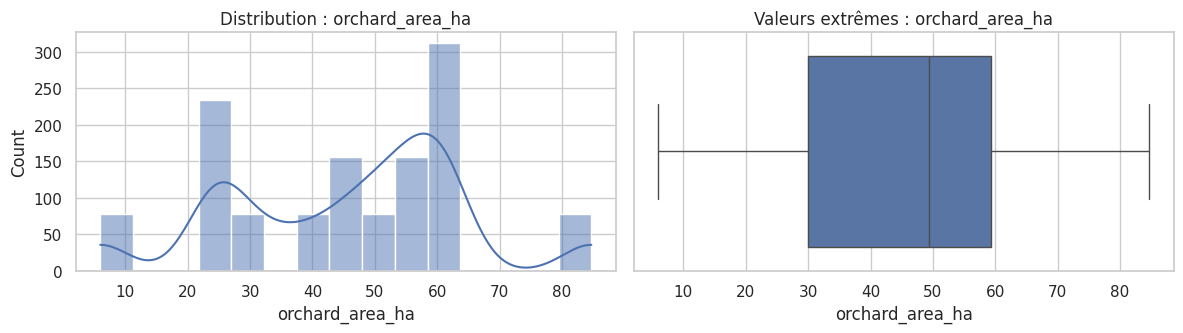

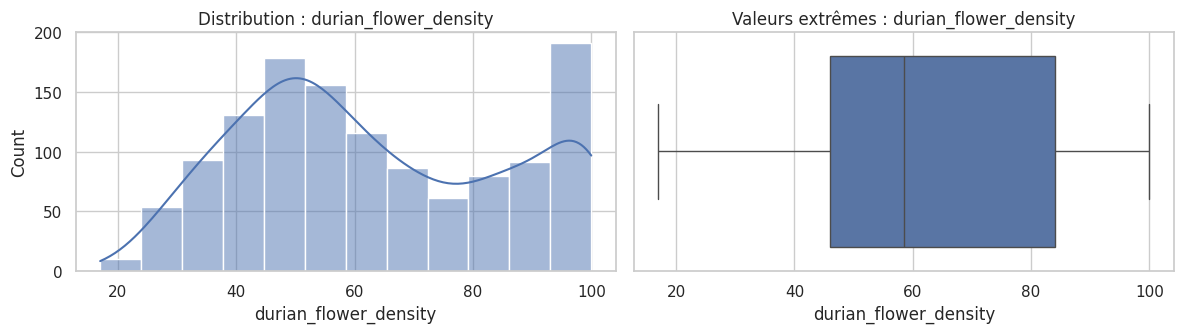

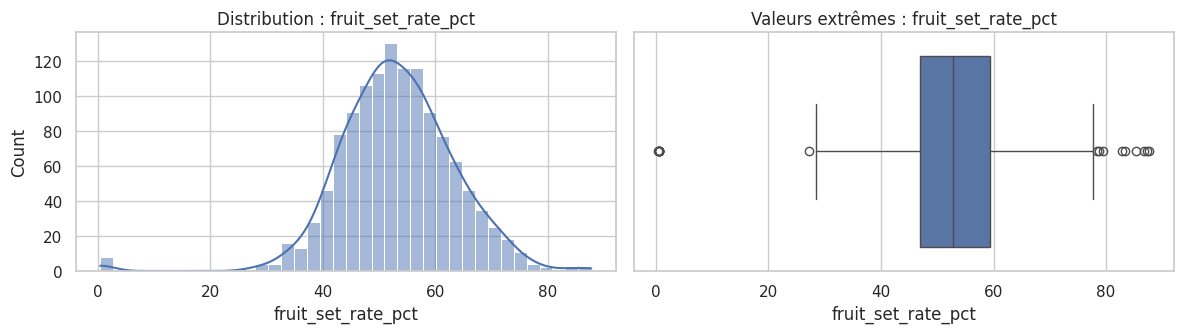

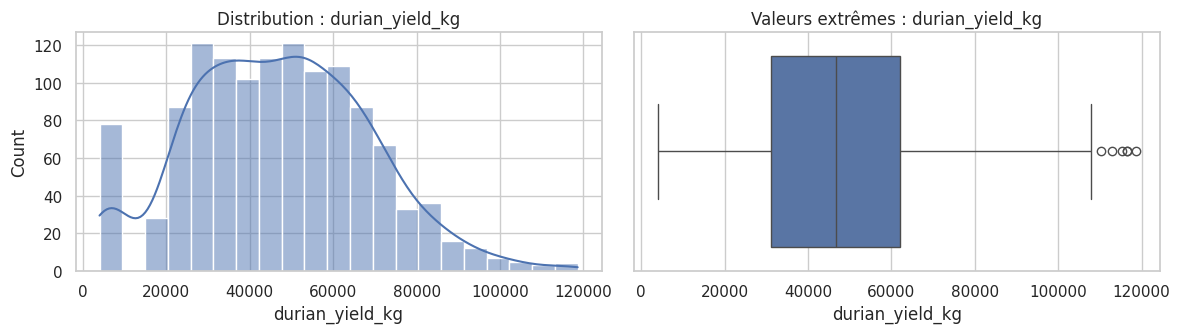

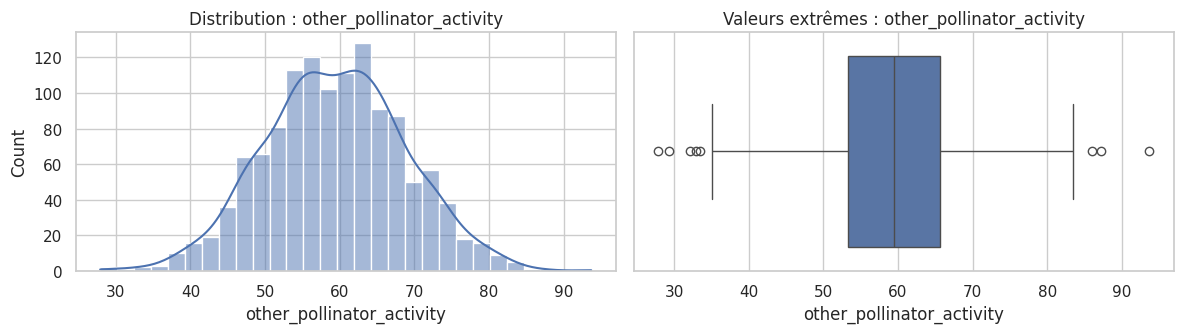

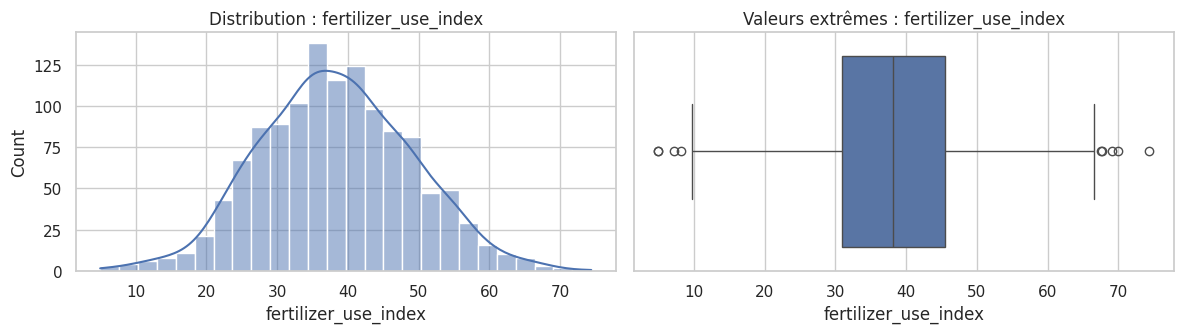

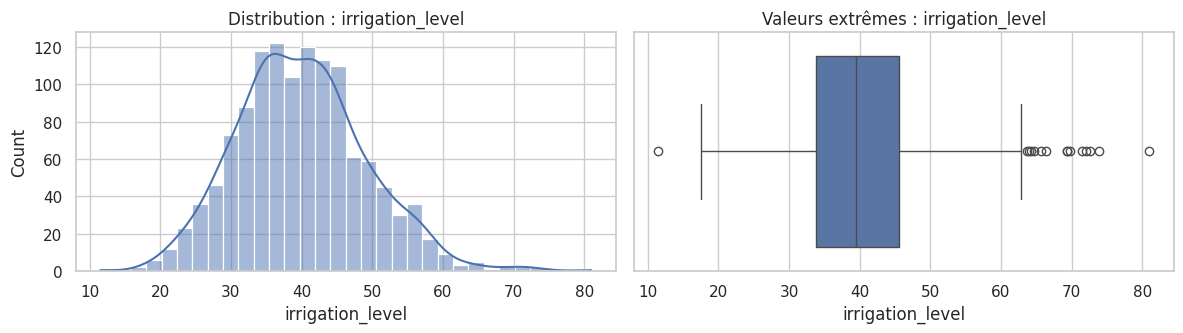

,variable,borne_basse_IQR,borne_haute_IQR,nb_valeurs_extremes
0,orchard_area_ha,-14.2375,103.4625,0
1,durian_flower_density,-11.1000,141.1000,0
2,fruit_set_rate_pct,28.1500,78.1500,18
3,durian_yield_kg,-15060.1625,108281.3375,6
4,other_pollinator_activity,34.7000,84.3000,8
5,fertilizer_use_index,9.2125,67.3125,9
6,irrigation_level,16.2500,63.0500,15


In [6]:
colonnes_a_visualiser = [c for c in colonnes_numeriques if df[c].notna().any()]

for col in colonnes_a_visualiser:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution : {col}")
    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"Valeurs extrêmes : {col}")
    plt.tight_layout()
    plt.show()

# Repérage IQR des valeurs extrêmes, sans suppression automatique
resume_iqr = []
for col in colonnes_a_visualiser:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    nb = ((df[col] < bas) | (df[col] > haut)).sum()
    resume_iqr.append([col, bas, haut, int(nb)])
display(pd.DataFrame(resume_iqr, columns=["variable", "borne_basse_IQR", "borne_haute_IQR", "nb_valeurs_extremes"]))

## Corrélations et associations

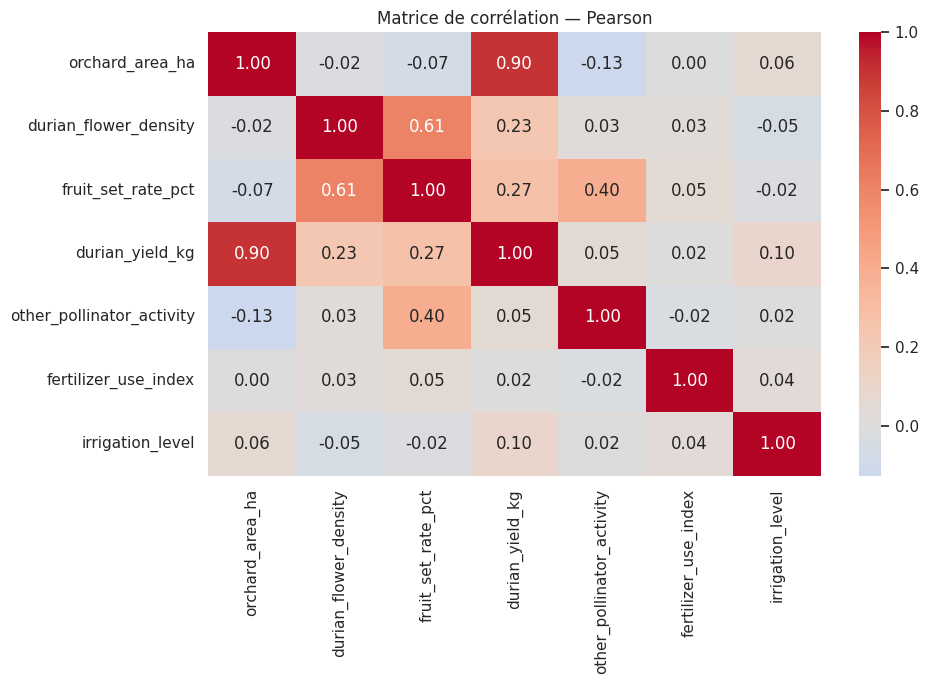

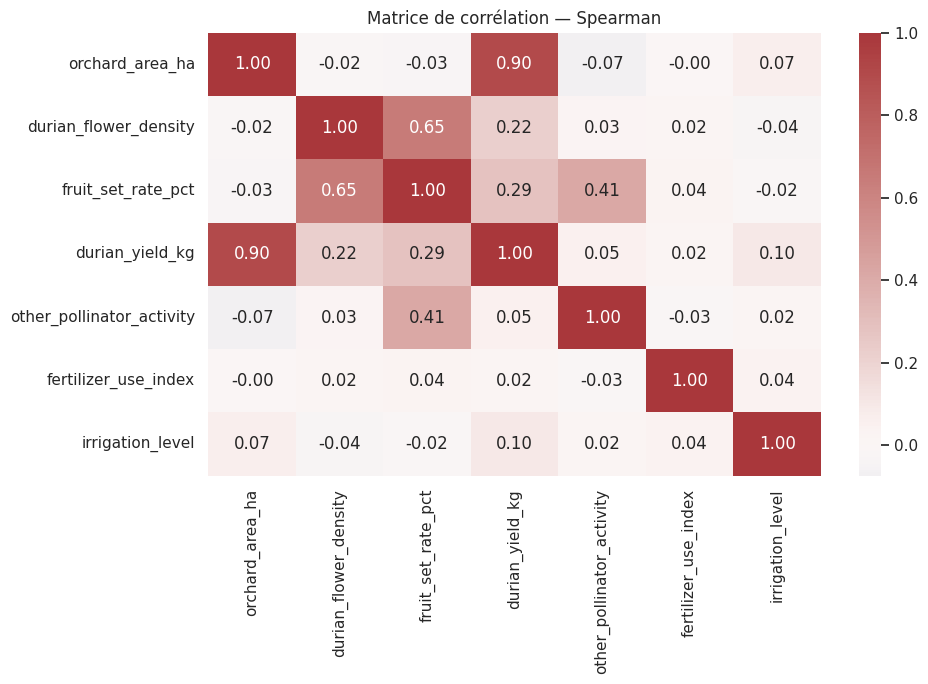

,correlation_spearman
durian_yield_kg,1.000000
orchard_area_ha,0.902146
fruit_set_rate_pct,0.286587
durian_flower_density,0.222743
irrigation_level,0.098348
other_pollinator_activity,0.049941
fertilizer_use_index,0.018071


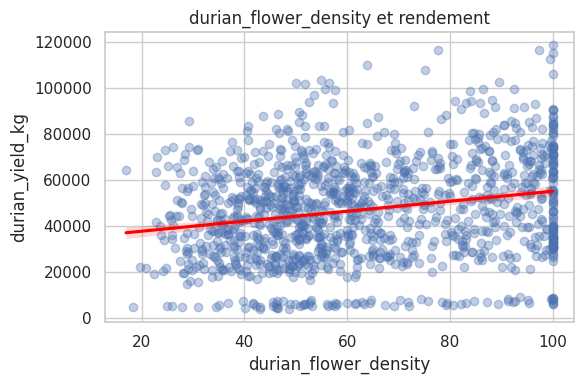

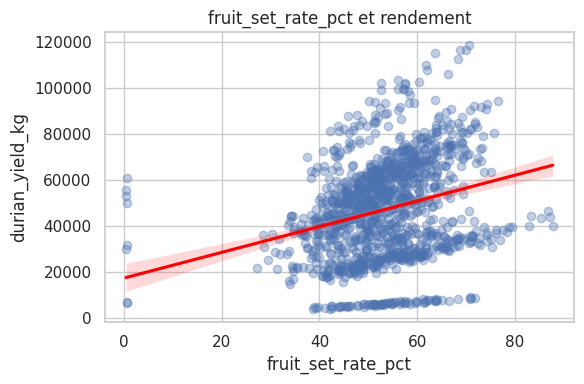

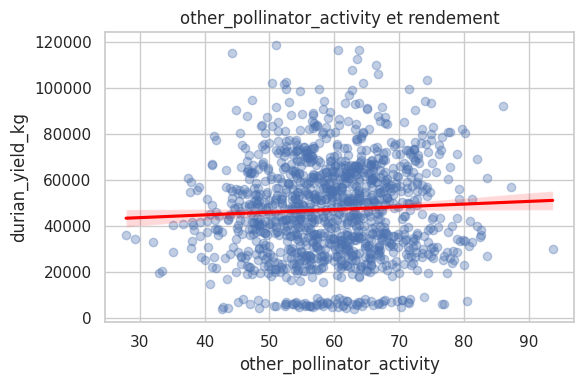

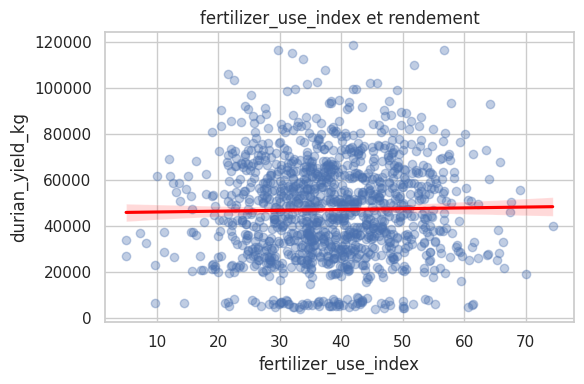

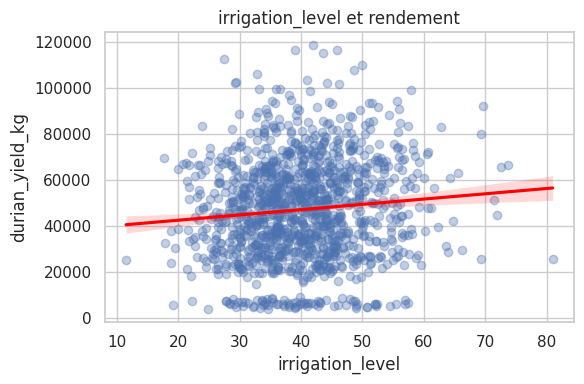

In [7]:
# Corrélations entre variables numériques
num = df[colonnes_numeriques].copy()

plt.figure(figsize=(10, 7))
sns.heatmap(num.corr(method="pearson"), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matrice de corrélation — Pearson")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(num.corr(method="spearman"), annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Matrice de corrélation — Spearman")
plt.tight_layout()
plt.show()

# Corrélations avec le rendement
display(num.corr(method="spearman")["durian_yield_kg"].sort_values(ascending=False).to_frame("correlation_spearman"))

# Nuages de points pour examiner les relations principales
for x in ["durian_flower_density", "fruit_set_rate_pct", "other_pollinator_activity", "fertilizer_use_index", "irrigation_level"]:
    plt.figure(figsize=(6, 4))
    sns.regplot(data=df, x=x, y="durian_yield_kg", scatter_kws={"alpha": 0.35}, line_kws={"color": "red"})
    plt.title(f"{x} et rendement")
    plt.tight_layout()
    plt.show()

##  Encodage One-Hot et classification avec matrice de confusion


- rendement_eleve = 1 si le rendement est supérieur ou égal à la médiane calculée sur les données d'entraînement ;
- rendement_eleve = 0 sinon.



Train : (1152, 14) | Test : (96, 14)
Seuil de rendement élevé : 46538.3 kg
\nRapport de classification
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.94      0.94      0.94        53

    accuracy                           0.94        96
   macro avg       0.94      0.94      0.94        96
weighted avg       0.94      0.94      0.94        96



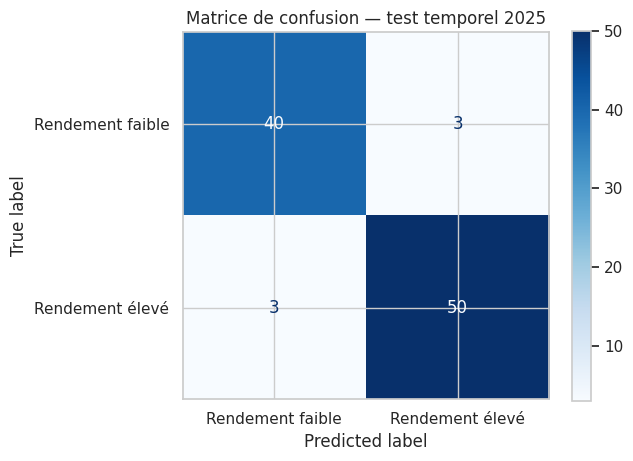

In [8]:
# Variables temporelles
df["annee"] = df["survey_period"].dt.year
df["mois"] = df["survey_period"].dt.month

# Séparation temporelle : apprentissage avant 2025, test en 2025
train = df[df["survey_period"] < "2025-01-01"].copy()
test = df[df["survey_period"] >= "2025-01-01"].copy()

print("Train :", train.shape, "| Test :", test.shape)

variables_num = [
    "orchard_area_ha",
    "durian_flower_density",
    "fruit_set_rate_pct",
    "other_pollinator_activity",
    "fertilizer_use_index",
    "irrigation_level",
    "mois"
]
variables_cat = ["site_code"]

# Seuil défini uniquement à partir de la période d'entraînement
seuil_rendement = train["durian_yield_kg"].median()
train = train.dropna(subset=["durian_yield_kg"]).copy()
test = test.dropna(subset=["durian_yield_kg"]).copy()

y_train = (train["durian_yield_kg"] >= seuil_rendement).astype(int)
y_test = (test["durian_yield_kg"] >= seuil_rendement).astype(int)

X_train = train[variables_num + variables_cat]
X_test = test[variables_num + variables_cat]

preparation = ColumnTransformer(
    transformers=[
        ("numerique", Pipeline([
            ("imputation", SimpleImputer(strategy="median"))
        ]), variables_num),
        ("categoriel", Pipeline([
            ("imputation", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), variables_cat)
    ]
)

modele = Pipeline([
    ("preparation", preparation),
    ("classification", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

modele.fit(X_train, y_train)
predictions = modele.predict(X_test)

print("Seuil de rendement élevé :", round(seuil_rendement, 2), "kg")
print("\\nRapport de classification")
print(classification_report(y_test, predictions, zero_division=0))

cm = confusion_matrix(y_test, predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rendement faible", "Rendement élevé"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion — test temporel 2025")
plt.tight_layout()
plt.show()

## Clustering — K-Means et DBSCAN

,k,inertie,silhouette
0,2,5960.287716,0.189112
1,3,5339.606016,0.149887
2,4,4901.953745,0.142020
3,5,4555.012939,0.140802
4,6,4233.106645,0.145014
5,7,3992.177082,0.143365


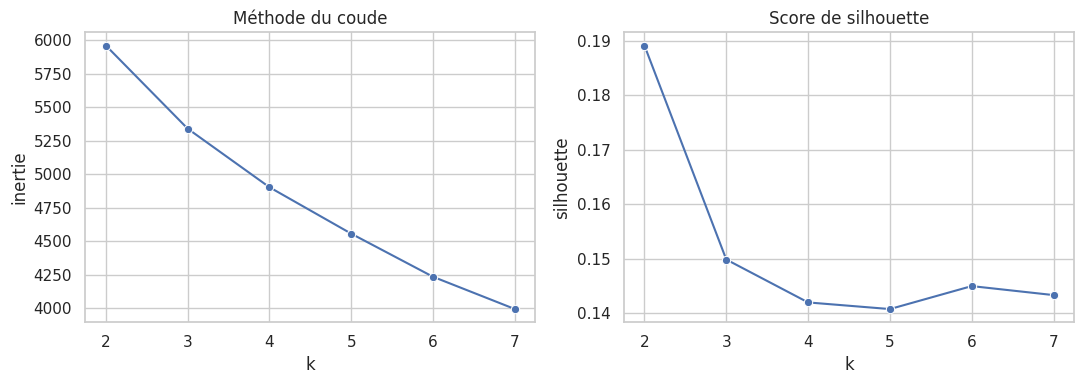

k retenu : 2


,effectif
cluster_kmeans,
0,671
1,577


,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level
cluster_kmeans,,,,,,
0,48.29,46.66,39728.09,56.82,37.7,39.86
1,80.42,60.81,55782.95,62.49,39.04,40.09


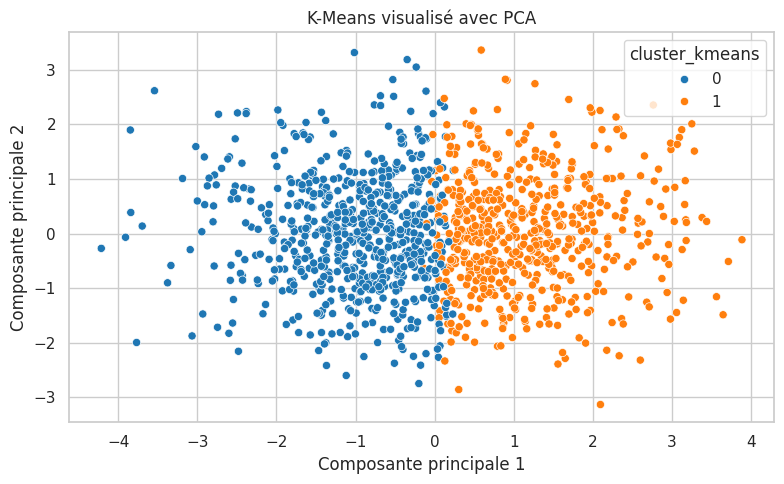

,effectif (-1 = bruit)
cluster_dbscan,
-1,201
0,1047


In [9]:
variables_cluster = [
    "durian_flower_density",
    "fruit_set_rate_pct",
    "durian_yield_kg",
    "other_pollinator_activity",
    "fertilizer_use_index",
    "irrigation_level"
]

donnees_cluster = df[variables_cluster].copy()
imputeur_cluster = SimpleImputer(strategy="median")
X_cluster = imputeur_cluster.fit_transform(donnees_cluster)
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# Choix de k avec inertie et silhouette
resultats_k = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_cluster_scaled)
    resultats_k.append([k, km.inertia_, silhouette_score(X_cluster_scaled, labels)])

resultats_k = pd.DataFrame(resultats_k, columns=["k", "inertie", "silhouette"])
display(resultats_k)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.lineplot(data=resultats_k, x="k", y="inertie", marker="o", ax=axes[0])
axes[0].set_title("Méthode du coude")
sns.lineplot(data=resultats_k, x="k", y="silhouette", marker="o", ax=axes[1])
axes[1].set_title("Score de silhouette")
plt.tight_layout()
plt.show()

# Choisir k après lecture des deux graphiques.
# Valeur initiale = k ayant la meilleure silhouette ; à discuter avec le coude.
k_retenu = int(resultats_k.loc[resultats_k["silhouette"].idxmax(), "k"])
kmeans = KMeans(n_clusters=k_retenu, random_state=42, n_init=20)
df["cluster_kmeans"] = kmeans.fit_predict(X_cluster_scaled)

print("k retenu :", k_retenu)
display(df["cluster_kmeans"].value_counts().sort_index().to_frame("effectif"))
display(df.groupby("cluster_kmeans")[variables_cluster].mean().round(2))

# Visualisation 2D via PCA
pca = PCA(n_components=2, random_state=42)
projection = pca.fit_transform(X_cluster_scaled)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=projection[:, 0], y=projection[:, 1], hue=df["cluster_kmeans"], palette="tab10", s=35)
plt.title("K-Means visualisé avec PCA")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.tight_layout()
plt.show()

# DBSCAN : méthode complémentaire, sensible aux paramètres
dbscan = DBSCAN(eps=1.2, min_samples=8)
df["cluster_dbscan"] = dbscan.fit_predict(X_cluster_scaled)
display(df["cluster_dbscan"].value_counts().sort_index().to_frame("effectif (-1 = bruit)"))

##  Détection d'anomalies

In [10]:
# Isolation Forest
iso = IsolationForest(contamination=0.03, random_state=42)
df["anomalie_if"] = (iso.fit_predict(X_cluster_scaled) == -1)

# Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
df["anomalie_lof"] = (lof.fit_predict(X_cluster_scaled) == -1)

print("Isolation Forest :")
display(df["anomalie_if"].value_counts().rename(index={False: "Normale", True: "Anomalie"}).to_frame("effectif"))
print("LOF :")
display(df["anomalie_lof"].value_counts().rename(index={False: "Normale", True: "Anomalie"}).to_frame("effectif"))

print("Comparaison des méthodes")
display(pd.crosstab(df["anomalie_if"], df["anomalie_lof"], rownames=["Isolation Forest"], colnames=["LOF"]))

print("Anomalies les plus marquées selon Isolation Forest")
display(df.loc[df["anomalie_if"], ["orchard_survey_id", "site_code", "survey_period"] + variables_cluster].head(20))

# Comparaison avec les notes de perturbation
display(pd.crosstab(df["has_disturbance_note"], df["anomalie_if"], normalize="index").round(3) * 100)

Isolation Forest :


,effectif
anomalie_if,
Normale,1210
Anomalie,38


LOF :


,effectif
anomalie_lof,
Normale,1210
Anomalie,38


Comparaison des méthodes


LOF,False,True
Isolation Forest,,
False,1194,16
True,16,22


Anomalies les plus marquées selon Isolation Forest


,orchard_survey_id,site_code,survey_period,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level
47,ORC-0000048,AVL-MAR,2022-12-01,57.7,63.0,26289.4,77.8,62.2,25.5
90,ORC-0000091,AVL-VEL,2020-01-01,36.7,51.0,60842.8,83.5,58.4,58.1
107,ORC-0000108,AVL-VEL,2021-06-01,96.6,74.2,93282.4,63.2,64.2,45.0
114,ORC-0000115,AVL-VEL,2022-01-01,49.9,57.3,61747.1,59.6,12.1,22.7
218,ORC-0000219,AVL-ORR,2024-03-01,69.1,59.8,80178.5,75.0,36.7,69.4
335,ORC-0000336,AVL-NFR,2020-12-01,51.1,38.6,19354.2,33.0,56.9,33.6
352,ORC-0000353,AVL-NFR,2022-05-01,100.0,53.8,26439.6,49.7,12.8,27.1
379,ORC-0000380,AVL-NFR,2024-08-01,61.8,43.9,19195.9,47.3,70.0,27.8
391,ORC-0000392,AVL-GRB,2019-02-01,25.9,31.8,34542.2,29.3,51.4,54.7
406,ORC-0000407,AVL-GRB,2020-05-01,100.0,53.1,55799.8,45.3,69.1,23.3


anomalie_if,False,True
has_disturbance_note,,
0,97.0,3.0
1,95.7,4.3


**Précaution :** `contamination=0.03` demande aux algorithmes de signaler environ 3 % d'observations comme anomalies. Ce pourcentage est un paramètre choisi, pas une proportion de défauts connue dans les données. Une anomalie statistique n'est pas nécessairement une erreur.

##  Graph Mining — réseau de similarité entre vergers

Nombre de nœuds : 16
Nombre de liens : 33
Composantes connexes : 1


,degree,betweenness,weighted_degree
AVL-NMQ,0.400000,0.266667,2.010045
AVL-ECJ,0.400000,0.209524,1.952274
AVL-NFR,0.333333,0.219048,1.756754
TMB-HQL,0.333333,0.085714,1.550248
AVL-ORR,0.333333,0.085714,1.548900
TMB-SKZ,0.333333,0.076190,1.482426
AVL-MAR,0.266667,0.104762,1.198602
AVL-TRP,0.266667,0.038095,1.191588
AVL-RBC,0.266667,0.009524,1.153755
AVL-HUA,0.266667,0.028571,1.114371


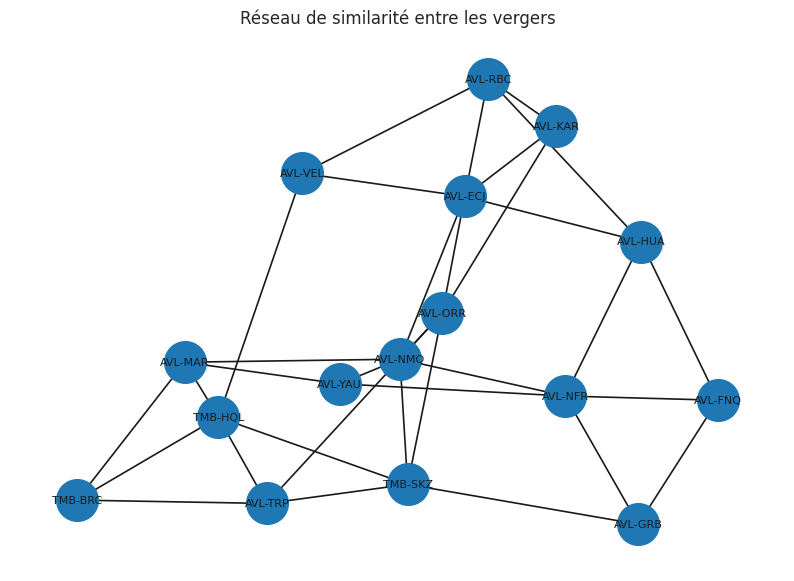

In [11]:
# Agréger les indicateurs par site pour construire un profil moyen par verger
profil_sites = df.groupby("site_code")[variables_cluster].mean()
profil_sites = profil_sites.fillna(profil_sites.median())

X_sites = StandardScaler().fit_transform(profil_sites)

# Chaque site est relié à ses 3 sites les plus proches selon les indicateurs agricoles.
k_voisins = min(4, len(profil_sites))  # inclut le site lui-même
voisins = NearestNeighbors(n_neighbors=k_voisins, metric="euclidean")
voisins.fit(X_sites)
distances, indices = voisins.kneighbors(X_sites)

G = nx.Graph()
for site in profil_sites.index:
    G.add_node(site)

for i, site in enumerate(profil_sites.index):
    for distance, j in zip(distances[i][1:], indices[i][1:]):
        autre_site = profil_sites.index[j]
        poids = 1 / (1 + distance)
        G.add_edge(site, autre_site, weight=poids, distance=distance)

print("Nombre de nœuds :", G.number_of_nodes())
print("Nombre de liens :", G.number_of_edges())
print("Composantes connexes :", nx.number_connected_components(G))

centralites = pd.DataFrame({
    "degree": pd.Series(nx.degree_centrality(G)),
    "betweenness": pd.Series(nx.betweenness_centrality(G, weight="distance")),
    "weighted_degree": pd.Series(dict(G.degree(weight="weight")))
}).sort_values("weighted_degree", ascending=False)
display(centralites)

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, seed=42, weight="weight")
nx.draw_networkx(G, pos, with_labels=True, node_size=900, font_size=8, width=1.2)
plt.title("Réseau de similarité entre les vergers")
plt.axis("off")
plt.show()

Le graphe relie les vergers ayant des profils agricoles proches. Il s'agit d'un réseau de similarité construit à partir des moyennes des indicateurs, et non d'un réseau de relations réelles entre exploitants. Les centralités indiquent la position dans ce réseau construit.

##  Mining Text and Other Unstructured Data — notes de terrain

In [12]:
notes = df["agricultural_disturbance_note"].dropna().astype(str)
print("Nombre de notes disponibles :", len(notes))
print("Notes distinctes :", notes.nunique())
display(notes.value_counts())

if len(notes) >= 2 and notes.nunique() >= 2:
    # Corpus très réduit : résultat descriptif uniquement.
    tfidf = TfidfVectorizer(max_features=20, stop_words="english", ngram_range=(1, 2))
    matrice = tfidf.fit_transform(notes)
    scores = np.asarray(matrice.mean(axis=0)).ravel()
    mots = pd.DataFrame({
        "terme": tfidf.get_feature_names_out(),
        "score_tfidf_moyen": scores
    }).sort_values("score_tfidf_moyen", ascending=False)
    display(mots)
else:
    print("Trop peu de notes distinctes pour une analyse TF-IDF pertinente.")

# Les catégories de perturbation après normalisation
display(df["agricultural_disturbance_note"].value_counts(dropna=False))

Nombre de notes disponibles : 23
Notes distinctes : 4


,count
agricultural_disturbance_note,
storm-related flower loss,15
storm-related flower loss,3
elevated pesticide application,3
elevated pesticide application,2


,terme,score_tfidf_moyen
3,flower,0.295798
9,related flower,0.295798
5,loss,0.295798
4,flower loss,0.295798
10,storm,0.295798
11,storm related,0.295798
8,related,0.295798
0,application,0.097220
2,elevated pesticide,0.097220
1,elevated,0.097220


,count
agricultural_disturbance_note,
<NA>,1225
storm-related flower loss,15
storm-related flower loss,3
elevated pesticide application,3
elevated pesticide application,2


seules 23 lignes environ contiennent une note. Les mots extraits ne représentent donc pas nécessairement l'ensemble des perturbations agricoles. On conserve les notes manquantes comme manquantes ; on ne les transforme pas en commentaire « aucun ».

## Mining Spatial and Temporal Data

 Analyse temporelle

Le CSV contient survey_period, mais pas de latitude/longitude. L'analyse temporelle est donc directement possible. L'analyse spatiale nécessite de rattacher les coordonnées de monitoring_sites.csv via site_code.

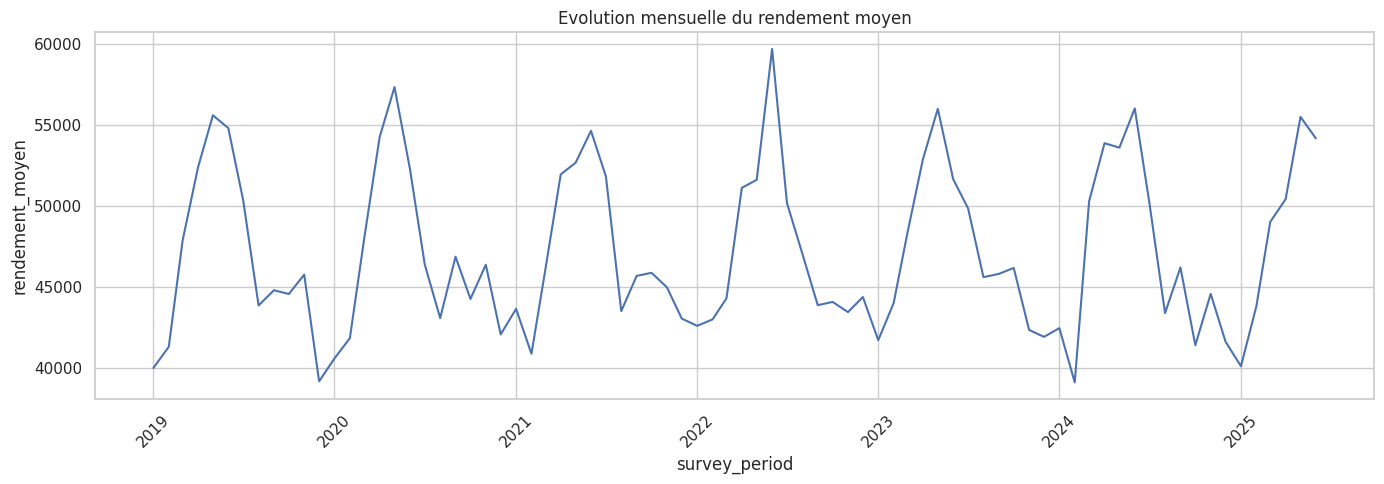

,durian_yield_kg,durian_flower_density,fruit_set_rate_pct
annee,,,
2019,46731.99,62.49,52.67
2020,46969.62,63.64,52.43
2021,47087.98,62.14,52.92
2022,47134.33,62.28,53.98
2023,47217.82,62.31,53.2
2024,46909.04,62.77,52.79
2025,48860.06,69.66,55.6


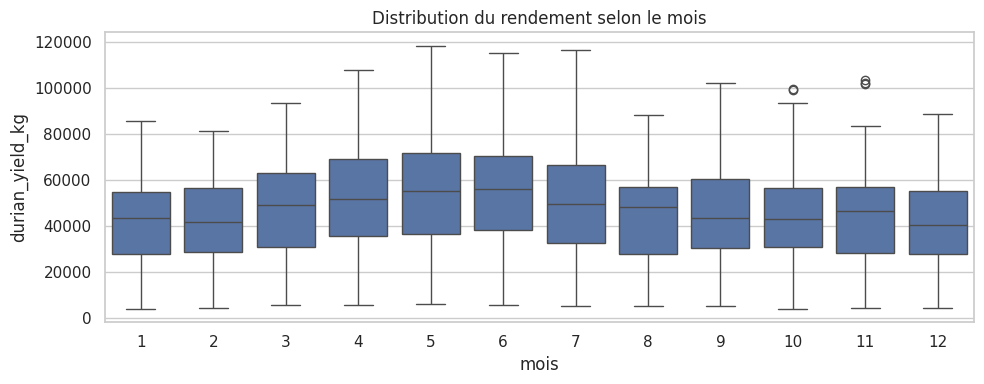

In [13]:
# Evolution mensuelle du rendement moyen
serie_temps = (
    df.dropna(subset=["survey_period"])
      .groupby("survey_period")
      .agg(
          rendement_moyen=("durian_yield_kg", "mean"),
          fleurs_moyennes=("durian_flower_density", "mean"),
          nouaison_moyenne=("fruit_set_rate_pct", "mean"),
          nb_enquetes=("orchard_survey_id", "count")
      )
      .reset_index()
)

plt.figure(figsize=(14, 5))
sns.lineplot(data=serie_temps, x="survey_period", y="rendement_moyen")
plt.title("Evolution mensuelle du rendement moyen")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Moyennes par année
df["annee"] = df["survey_period"].dt.year
display(df.groupby("annee")[["durian_yield_kg", "durian_flower_density", "fruit_set_rate_pct"]].mean().round(2))

# Comparaison des mois
df["mois"] = df["survey_period"].dt.month
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="mois", y="durian_yield_kg")
plt.title("Distribution du rendement selon le mois")
plt.tight_layout()
plt.show()

Colonnes disponibles dans monitoring_sites : ['site_code', 'site_name', 'site_category', 'region', 'jurisdiction', 'latitude', 'longitude', 'elevation_m', 'habitat_category', 'cave_access_category', 'orchard_context', 'programme_start_date', 'programme_end_date', 'site_status']
Sites sans coordonnées après jointure : 0


,site_code,rendement_moyen,fleurs_moyennes,nouaison_moyenne,nb_enquetes,latitude,longitude
0,AVL-ECJ,64220.921795,61.755128,53.494872,78,7.5053,101.3874
1,AVL-FNQ,35135.692308,60.417949,47.773077,78,7.3956,101.9351
2,AVL-GRB,48921.521795,62.376923,45.428103,78,7.3725,102.0928
3,AVL-HUA,44365.641026,60.694872,48.471795,78,7.7014,101.8681
4,AVL-KAR,85616.562821,61.224359,50.908974,78,7.4089,101.6084


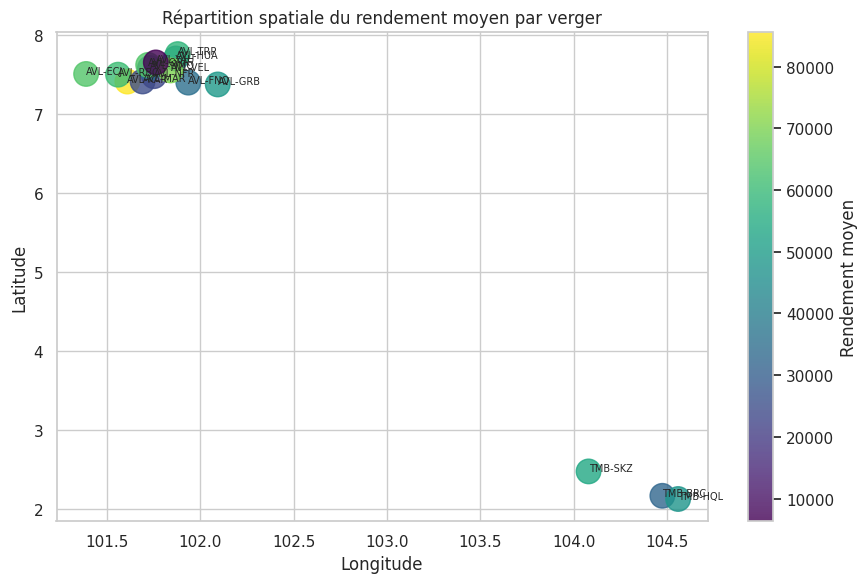

In [14]:
# 10.2 Analyse spatiale facultative par jointure avec monitoring_sites.csv
# Charger le fichier si vous l'avez dans le même dossier Colab.
try:
    sites = pd.read_csv("monitoring_sites.csv")
    print("Colonnes disponibles dans monitoring_sites :", sites.columns.tolist())

    # Repérage souple des colonnes de coordonnées
    colonnes_lower = {c.lower(): c for c in sites.columns}
    lat_col = next((colonnes_lower[c] for c in ["latitude", "lat"] if c in colonnes_lower), None)
    lon_col = next((colonnes_lower[c] for c in ["longitude", "lon", "long"] if c in colonnes_lower), None)

    if lat_col and lon_col and "site_code" in sites.columns:
        moyennes_sites = df.groupby("site_code").agg(
            rendement_moyen=("durian_yield_kg", "mean"),
            fleurs_moyennes=("durian_flower_density", "mean"),
            nouaison_moyenne=("fruit_set_rate_pct", "mean"),
            nb_enquetes=("orchard_survey_id", "count")
        ).reset_index()

        spatial = moyennes_sites.merge(
            sites[["site_code", lat_col, lon_col]].drop_duplicates("site_code"),
            on="site_code",
            how="left",
            validate="one_to_one"
        )

        print("Sites sans coordonnées après jointure :", spatial[[lat_col, lon_col]].isna().any(axis=1).sum())
        display(spatial.head())

        plt.figure(figsize=(9, 6))
        points = plt.scatter(
            spatial[lon_col], spatial[lat_col],
            c=spatial["rendement_moyen"], s=spatial["nb_enquetes"] * 4,
            cmap="viridis", alpha=0.8
        )
        plt.colorbar(points, label="Rendement moyen")
        for _, ligne in spatial.dropna(subset=[lat_col, lon_col]).iterrows():
            plt.text(ligne[lon_col], ligne[lat_col], ligne["site_code"], fontsize=7)
        plt.xlabel("Longitude")
        plt.ylabel("Latitude")
        plt.title("Répartition spatiale du rendement moyen par verger")
        plt.tight_layout()
        plt.show()
    else:
        print("Coordonnées ou site_code introuvables : vérifier les noms de colonnes du fichier sites.")
except FileNotFoundError:
    print("monitoring_sites.csv non trouvé. Déposer ce fichier dans Colab pour réaliser la partie spatiale.")

 Apriori — recherche d'associations

In [15]:
# Installer mlxtend si nécessaire dans Colab
!pip -q install mlxtend

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

df_ap = df.copy()

variables_apriori = [
    "durian_flower_density",
    "fruit_set_rate_pct",
    "durian_yield_kg",
    "other_pollinator_activity",
    "fertilizer_use_index",
    "irrigation_level"
]

transactions = []
for _, ligne in df_ap.iterrows():
    elements = []
    for col in variables_apriori:
        valeur = ligne[col]
        if pd.notna(valeur):
            try:
                classes = pd.qcut(
                    df_ap[col].dropna(),
                    q=3,
                    labels=["faible", "moyen", "eleve"],
                    duplicates="drop"
                )
                # Reconstituer les seuils à partir de la distribution de la colonne
                q1, q2 = df_ap[col].quantile([1/3, 2/3])
                if valeur <= q1:
                    niveau = "faible"
                elif valeur <= q2:
                    niveau = "moyen"
                else:
                    niveau = "eleve"
                elements.append(f"{col}_{niveau}")
            except Exception:
                pass

    note = ligne["agricultural_disturbance_note"]
    if pd.notna(note):
        elements.append("perturbation_" + str(note).replace(" ", "_"))

    transactions.append(elements)

te = TransactionEncoder()
tableau = te.fit(transactions).transform(transactions)
transactions_df = pd.DataFrame(tableau, columns=te.columns_)

frequents = apriori(
    transactions_df,
    min_support=0.08,
    use_colnames=True,
    max_len=3
).sort_values("support", ascending=False)

print("Itemsets fréquents")
display(frequents.head(25))

if len(frequents) > 0:
    regles = association_rules(frequents, metric="confidence", min_threshold=0.5)
    if len(regles) > 0:
        regles = regles.sort_values(["lift", "confidence"], ascending=False)
        display(regles[["antecedents", "consequents", "support", "confidence", "lift"]].head(20))
    else:
        print("Aucune règle ne dépasse le seuil de confiance choisi.")
else:
    print("Aucun itemset trouvé : diminuer min_support avec prudence.")

Itemsets fréquents


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
11,0.338942,(fruit_set_rate_pct_moyen)
7,0.336538,(fertilizer_use_index_faible)
17,0.335737,(other_pollinator_activity_moyen)
14,0.334936,(irrigation_level_moyen)
10,0.334936,(fruit_set_rate_pct_faible)
16,0.334936,(other_pollinator_activity_faible)
1,0.333333,(durian_flower_density_faible)
2,0.333333,(durian_flower_density_moyen)
4,0.333333,(durian_yield_kg_faible)
0,0.333333,(durian_flower_density_eleve)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
17,"(durian_flower_density_eleve, other_pollinator...",(fruit_set_rate_pct_eleve),0.087340,0.893443,2.739598
11,"(other_pollinator_activity_faible, durian_flow...",(fruit_set_rate_pct_faible),0.108173,0.888158,2.651725
7,"(durian_flower_density_eleve, durian_yield_kg_...",(fruit_set_rate_pct_eleve),0.112981,0.750000,2.299754
16,"(durian_yield_kg_moyen, durian_flower_density_...",(fruit_set_rate_pct_faible),0.091346,0.740260,2.210153
20,"(other_pollinator_activity_moyen, fruit_set_ra...",(durian_flower_density_eleve),0.084936,0.736111,2.208333
19,"(durian_flower_density_eleve, other_pollinator...",(fruit_set_rate_pct_eleve),0.084936,0.711409,2.181422
23,"(irrigation_level_moyen, fruit_set_rate_pct_fa...",(durian_flower_density_faible),0.080929,0.706294,2.118881
9,"(durian_yield_kg_eleve, fruit_set_rate_pct_eleve)",(durian_flower_density_eleve),0.112981,0.691176,2.073529
24,"(durian_flower_density_faible, irrigation_leve...",(fruit_set_rate_pct_faible),0.080929,0.691781,2.065413
14,"(durian_flower_density_faible, durian_yield_kg...",(fruit_set_rate_pct_faible),0.092949,0.690476,2.061517


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [16]:

# ==========================================
# 13. EXTRACTION AUTOMATIQUE POUR LA SYNTHESE FINALE
# ==========================================

rapport = []

def ajouter(titre, contenu):
    rapport.append(f"\n{'='*65}\n{titre}\n{'='*65}\n{contenu}")

# 1. STRUCTURE ET NETTOYAGE
ajouter(
    "1. STRUCTURE ET NETTOYAGE",
    f"""
Nombre de lignes après nettoyage : {len(df)}
Nombre de colonnes : {len(df.columns)}
Nombre de sites : {df['site_code'].nunique()}
Doublons exacts restants : {df.duplicated().sum()}
Identifiants d'enquête distincts : {df['orchard_survey_id'].nunique()}

Valeurs manquantes :
{df.isna().sum().to_string()}

Statistiques des variables numériques :
{df[colonnes_numeriques].describe().round(2).to_string()}
"""
)

# 2. CORRELATIONS
correlations = df[colonnes_numeriques].corr(method="spearman")["durian_yield_kg"]
correlations = correlations.drop("durian_yield_kg").sort_values(
    key=abs, ascending=False
)

ajouter(
    "2. CORRELATIONS AVEC LE RENDEMENT (SPEARMAN)",
    correlations.round(3).to_string()
)

# 3. CLASSIFICATION ET MATRICE DE CONFUSION
if "predictions" in globals() and "y_test" in globals():
    from sklearn.metrics import classification_report, confusion_matrix

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    scores = classification_report(
        y_test, predictions,
        target_names=["Rendement faible", "Rendement élevé"],
        output_dict=True,
        zero_division=0
    )

    ajouter(
        "3. CLASSIFICATION",
        f"""
Seuil de rendement : {seuil_rendement:.2f} kg

Matrice de confusion :
{cm}

Rapport de classification :
{pd.DataFrame(scores).T.round(3).to_string()}
"""
    )
else:
    ajouter("3. CLASSIFICATION", "Résultats non disponibles : exécuter la cellule de classification.")

# 4. CLUSTERING
if "cluster_kmeans" in df.columns:
    effectifs = df["cluster_kmeans"].value_counts().sort_index()
    moyennes = df.groupby("cluster_kmeans")[variables_cluster].mean()

    ajouter(
        "4. CLUSTERING K-MEANS",
        f"""
Nombre de clusters : {df['cluster_kmeans'].nunique()}

Effectifs :
{effectifs.to_string()}

Caractéristiques moyennes :
{moyennes.round(2).to_string()}
"""
    )

if "cluster_dbscan" in df.columns:
    ajouter(
        "DBSCAN",
        df["cluster_dbscan"].value_counts().sort_index().to_string()
    )

# 5. DETECTION D'ANOMALIES
if "anomalie_if" in df.columns:
    ajouter(
        "5. ISOLATION FOREST",
        f"""
Répartition :
{df['anomalie_if'].value_counts().to_string()}

Sites les plus concernés :
{df.loc[df['anomalie_if'], 'site_code'].value_counts().head(10).to_string()}

Codes des observations signalées :
{df.loc[df['anomalie_if'], variables_cluster].describe().round(2).to_string()}
"""
    )

if "anomalie_lof" in df.columns:
    ajouter(
        "LOF",
        df["anomalie_lof"].value_counts().to_string()
    )

if "anomalie_if" in df.columns and "anomalie_lof" in df.columns:
    ajouter(
        "COMPARAISON ISOLATION FOREST / LOF",
        pd.crosstab(df["anomalie_if"], df["anomalie_lof"]).to_string()
    )

# 6. GRAPH MINING
if "G" in globals() and "centralites" in globals():
    ajouter(
        "6. GRAPH MINING",
        f"""
Nombre de nœuds : {G.number_of_nodes()}
Nombre de liens : {G.number_of_edges()}
Composantes connexes : {nx.number_connected_components(G)}

Sites les plus centraux :
{centralites.head(10).round(3).to_string()}
"""
    )

# 7. TEXT MINING
if "notes" in globals():
    ajouter(
        "7. TEXT MINING",
        f"""
Nombre de notes renseignées : {len(notes)}
Nombre de notes distinctes : {notes.nunique()}

Notes les plus fréquentes :
{notes.value_counts().head(15).to_string()}
"""
    )

if "mots" in globals() and isinstance(mots, pd.DataFrame):
    ajouter("MOTS-CLES TF-IDF", mots.head(15).round(3).to_string(index=False))

# 8. ANALYSE TEMPORELLE
if "serie_temps" in globals():
    ajouter(
        "8. ANALYSE TEMPORELLE",
        f"""
Période étudiée :
{df['survey_period'].min()} à {df['survey_period'].max()}

Rendement moyen par année :
{df.groupby(df['survey_period'].dt.year)['durian_yield_kg'].mean().round(2).to_string()}

Evolution mensuelle :
{serie_temps[['survey_period', 'rendement_moyen', 'nb_enquetes']].tail(15).round(2).to_string(index=False)}
"""
    )

# 9. ANALYSE SPATIALE
if "spatial" in globals() and isinstance(spatial, pd.DataFrame):
    ajouter(
        "9. ANALYSE SPATIALE",
        spatial.sort_values("rendement_moyen", ascending=False)
        .head(15).round(3).to_string(index=False)
    )
else:
    ajouter(
        "9. ANALYSE SPATIALE",
        "Résultats spatiaux non disponibles ou jointure non réalisée."
    )

# 10. APRIORI
if "frequents" in globals():
    ajouter(
        "10. ITEMSETS FREQUENTS — APRIORI",
        frequents.head(15).to_string(index=False)
    )

if "regles" in globals() and isinstance(regles, pd.DataFrame) and len(regles) > 0:
    colonnes_regles = [
        c for c in ["antecedents", "consequents", "support", "confidence", "lift"]
        if c in regles.columns
    ]
    ajouter(
        "REGLES D'ASSOCIATION LES PLUS INTERESSANTES",
        regles.sort_values("lift", ascending=False)
        [colonnes_regles].head(15).round(3).to_string(index=False)
    )
else:
    ajouter("REGLES APRIORI", "Aucune règle disponible.")

# AFFICHAGE FINAL
synthese = "\n".join(rapport)

print(synthese)

# Sauvegarder les résultats dans un fichier texte
with open("synthese_orchard_surveys.txt", "w", encoding="utf-8") as fichier:
    fichier.write(synthese)

print("\nFichier créé : synthese_orchard_surveys.txt")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


1. STRUCTURE ET NETTOYAGE

Nombre de lignes après nettoyage : 1248
Nombre de colonnes : 18
Nombre de sites : 16
Doublons exacts restants : 0
Identifiants d'enquête distincts : 1248

Valeurs manquantes :
orchard_survey_id                   0
site_code                           0
survey_period                       0
orchard_area_ha                     0
durian_flower_density               0
fruit_set_rate_pct                  0
durian_yield_kg                     0
other_pollinator_activity           0
fertilizer_use_index                0
irrigation_level                    0
agricultural_disturbance_note    1225
has_disturbance_note                0
annee                               0
mois                                0
cluster_kmeans                      0
cluster_dbscan                      0
anomalie_if                         0
anomalie_lof                        0

Statistiques des variables numériques :
       orchard_area_ha  durian_flower_density  fruit_set_rate_pct  duri

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


#  Interprétation et synthèse des résultats

##  Qualité des données
Après nettoyage, le dataset contient **1 248 observations réparties sur 16 sites**, sans doublons. Cependant, 1 225 notes de terrain sont manquantes, ce qui limite l'analyse textuelle.

##  Corrélations avec le rendement
La surface du verger présente une très forte corrélation avec le rendement (0,902). Le taux de nouaison (0,287) et la densité de fleurs (0,223) présentent des relations plus modérées. La surface constitue donc le facteur le plus fortement associé au rendement total.

##  Classification et clustering
Le modèle Random Forest atteint une accuracy de **93,8 %** pour distinguer les rendements élevés et faibles. Cette classification repose toutefois sur un seuil construit à partir de la médiane.

K-Means identifie deux profils de vergers : le second présente une densité de fleurs, un taux de nouaison et un rendement moyens plus élevés que le premier.

##  Détection d'anomalies
Isolation Forest et LOF détectent chacun 38 anomalies, dont 22 communes aux deux méthodes. Le site **TMB-BRC concentre 10 anomalies** détectées par Isolation Forest. Ce site mérite donc une attention particulière lors du croisement avec les données de surveillance.

##  Graph Mining
Le graphe de similarité contient 16 sites et 33 liens. AVL-NMQ, AVL-ECJ et AVL-NFR présentent les centralités les plus importantes. Ces résultats décrivent les similarités entre les profils agricoles des sites.

##  Text Mining
Sur les 23 notes disponibles, **18 mentionnent des pertes de fleurs liées aux tempêtes** et 5 une application élevée de pesticides. Cette piste est intéressante à rapprocher des données de floraison et de rendement, même si le nombre de notes reste limité.

## Analyses temporelle et spatiale
Le rendement moyen reste relativement stable entre 2019 et 2024. Des différences importantes apparaissent cependant entre les sites : AVL-KAR possède le rendement moyen le plus élevé (environ 85 617 kg), tandis qu'AVL-NFR présente le plus faible (environ 23 882 kg).

Ces écarts pourraient être liés aux caractéristiques propres à chaque site et nécessitent une comparaison avec les données écologiques et opérationnelles.

## Apriori
Les règles d'association montrent un lien intéressant entre la floraison, l'activité des pollinisateurs et la nouaison. Une densité de fleurs et une activité des pollinisateurs élevées sont associées à une nouaison élevée (confiance de 89,3 %, lift de 2,74).

##  Conclusion et pistes de recherche
L'analyse révèle trois pistes principales :
- La surface des vergers est fortement associée au rendement total.
- La floraison et l'activité des pollinisateurs sont associées au taux de nouaison.
- Certains sites, notamment TMB-BRC, présentent des anomalies ou des rendements qui méritent une investigation plus approfondie.


